Clase 010 · `010_importar_formatos` · Último archivo del recorrido de importación: un CSV
exportado desde Windows cuyo encabezado trae acentos, `°` y `²`, y que `pandas` no puede
leer hasta que le dices con qué `encoding` fue escrito. La segunda mitad cambia de tema y
abre la unidad de visualización: la *anatomía de una figura* de la documentación de
matplotlib, que pone nombre a cada pieza que vas a usar en las libretas siguientes.

::: {.callout-important title="Datos"}
El archivo `v7_encoding.csv` no viaja en el repositorio; colócalo en
`clases/010_importar_formatos/data/001_raw/` (se comparte en clase).
:::

## Librerías

Además de `pandas` y `matplotlib` (se instalan en el proyecto con `uv add pandas matplotlib`),
importamos `numpy` y tres piezas internas de matplotlib —`Circle`, `withStroke` y los
localizadores de marcas— que sólo usa la figura de la anatomía al final. `plt` es el alias
universal de `matplotlib.pyplot`.

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from matplotlib.patches import Circle
from matplotlib.patheffects import withStroke
from matplotlib.ticker import AutoMinorLocator, MultipleLocator


## Leer el CSV con `encoding="cp1252"`

Si lees este archivo con `pd.read_csv(f)` a secas obtienes un `UnicodeDecodeError`: `pandas`
supone UTF-8 y el archivo fue guardado con la codificación de Windows en español, `cp1252`
(también llamada *Windows-1252*). El parámetro `encoding` le dice cómo interpretar cada byte;
`skiprows=2` salta las dos líneas de metadatos del principio y, como siempre, la columna 0 es
el índice de fechas.

Renombramos sólo las tres irradiancias a `dhi`, `dni` y `ghi`; el resto conserva su nombre
largo. Mira la salida de `info()`: los acentos, el `°` y el `²` ya se leen bien, hay 172 433
registros de abril a agosto de 2026 y la presión atmosférica es la columna con más huecos.

In [6]:
f = "../data/001_raw/v7_encoding.csv"
esolmet = pd.read_csv(f,encoding="cp1252",skiprows=2,index_col=0,parse_dates=True)
nombres = {
    "Irradiancia difusa (W/m²)":"dhi",
    "Irradiancia directa (W/m²)":"dni",
    "Irradiancia global (W/m²)":"ghi"
}
esolmet.rename(columns=nombres,inplace=True)
esolmet.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 172433 entries, 2026-04-08 00:00:00 to 2026-08-05 18:04:00
Data columns (total 10 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   dhi                           172433 non-null  float64
 1   dni                           172433 non-null  float64
 2   ghi                           172431 non-null  float64
 3   Presión atmosférica (hPa)     143686 non-null  float64
 4   Precipitación acumulada (mm)  172433 non-null  float64
 5   Humedad relativa (%)          171894 non-null  float64
 6   Temperatura (°C)              172433 non-null  float64
 7   Índice UV                     172433 non-null  float64
 8   Dirección viento (°)          172433 non-null  float64
 9   Velocidad viento (m/s)        172433 non-null  float64
dtypes: float64(10)
memory usage: 14.5 MB


## Anatomía de una figura

Esta celda viene de la [galería de matplotlib](https://matplotlib.org/stable/gallery/showcase/anatomy.html)
y no hace falta entenderla línea por línea: su valor es la figura que produce. Cada círculo
señala una pieza y, debajo, el método que la controla. Las dos jerarquías que importan:

- **`Figure`** (`plt.figure`) es el lienzo completo; puede contener uno o varios **`Axes`**.
- **`Axes`** (`fig.subplots`) es un sistema de ejes con su título, sus etiquetas, su rejilla,
  su leyenda y sus líneas. Casi todo lo que dibujas se hace con métodos de `ax`: `ax.plot`,
  `ax.set_xlabel`, `ax.grid`, `ax.legend`.

Cada *axis* (eje) tiene marcas mayores y menores (`set_major_locator`, `set_minor_locator`) y
formateadores que deciden qué texto llevan. Las *spines* son los cuatro bordes del área de
dibujo. Guarda esta figura como referencia: es el vocabulario de la unidad 4.

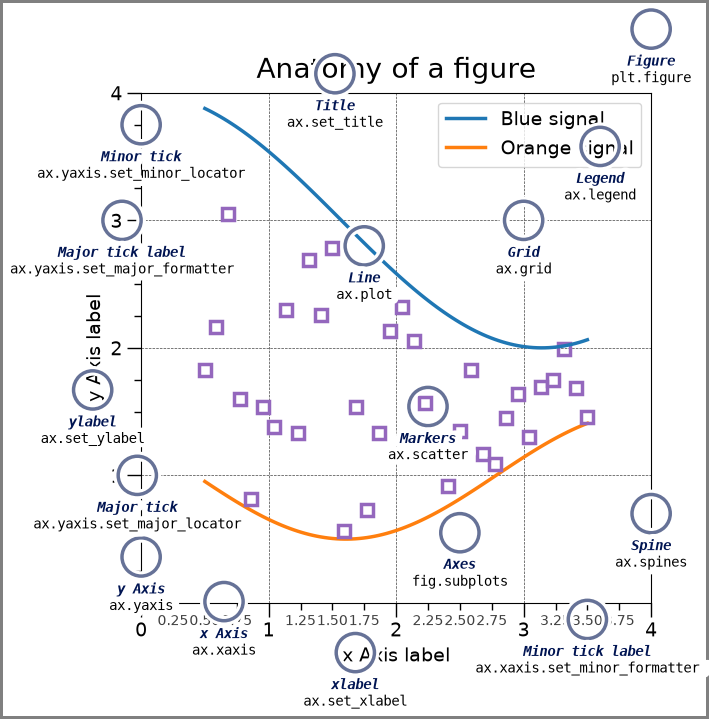

In [8]:
#| label: fig-anatomia-figura
#| fig-cap: "Anatomía de una figura de matplotlib, tomada de la galería oficial. Cada círculo señala un componente —título, ejes, marcas mayores y menores, etiquetas, rejilla, leyenda, líneas, marcadores, spines— y debajo aparece el método de `ax` o de `fig` que lo controla."
#| fig-alt: "Figura cuadrada con dos curvas, azul y naranja, cuadros morados dispersos y una rejilla punteada; círculos azules con etiquetas en cursiva señalan cada parte de la figura y el método de matplotlib correspondiente."
royal_blue = [0, 20/256, 82/256]


# make the figure

np.random.seed(19680801)

X = np.linspace(0.5, 3.5, 100)
Y1 = 3+np.cos(X)
Y2 = 1+np.cos(1+X/0.75)/2
Y3 = np.random.uniform(Y1, Y2, len(X))

fig = plt.figure(figsize=(7.5, 7.5))
ax = fig.add_axes((0.2, 0.17, 0.68, 0.7), aspect=1)

ax.xaxis.set_major_locator(MultipleLocator(1.000))
ax.xaxis.set_minor_locator(AutoMinorLocator(4))
ax.yaxis.set_major_locator(MultipleLocator(1.000))
ax.yaxis.set_minor_locator(AutoMinorLocator(4))
ax.xaxis.set_minor_formatter("{x:.2f}")

ax.set_xlim(0, 4)
ax.set_ylim(0, 4)

ax.tick_params(which='major', width=1.0, length=10, labelsize=14)
ax.tick_params(which='minor', width=1.0, length=5, labelsize=10,
               labelcolor='0.25')

ax.grid(linestyle="--", linewidth=0.5, color='.25', zorder=-10)

ax.plot(X, Y1, c='C0', lw=2.5, label="Blue signal", zorder=10)
ax.plot(X, Y2, c='C1', lw=2.5, label="Orange signal")
ax.plot(X[::3], Y3[::3], linewidth=0, markersize=9,
        marker='s', markerfacecolor='none', markeredgecolor='C4',
        markeredgewidth=2.5)

ax.set_title("Anatomy of a figure", fontsize=20, verticalalignment='bottom')
ax.set_xlabel("x Axis label", fontsize=14)
ax.set_ylabel("y Axis label", fontsize=14)
ax.legend(loc="upper right", fontsize=14)


# Annotate the figure

def annotate(x, y, text, code):
    # Circle marker
    c = Circle((x, y), radius=0.15, clip_on=False, zorder=10, linewidth=2.5,
               edgecolor=royal_blue + [0.6], facecolor='none',
               path_effects=[withStroke(linewidth=7, foreground='white')])
    ax.add_artist(c)

    # use path_effects as a background for the texts
    # draw the path_effects and the colored text separately so that the
    # path_effects cannot clip other texts
    for path_effects in [[withStroke(linewidth=7, foreground='white')], []]:
        color = 'white' if path_effects else royal_blue
        ax.text(x, y-0.2, text, zorder=100,
                ha='center', va='top', weight='bold', color=color,
                style='italic', fontfamily='monospace',
                path_effects=path_effects)

        color = 'white' if path_effects else 'black'
        ax.text(x, y-0.33, code, zorder=100,
                ha='center', va='top', weight='normal', color=color,
                fontfamily='monospace', fontsize='medium',
                path_effects=path_effects)


annotate(3.5, -0.13, "Minor tick label", "ax.xaxis.set_minor_formatter")
annotate(-0.03, 1.0, "Major tick", "ax.yaxis.set_major_locator")
annotate(0.00, 3.75, "Minor tick", "ax.yaxis.set_minor_locator")
annotate(-0.15, 3.00, "Major tick label", "ax.yaxis.set_major_formatter")
annotate(1.68, -0.39, "xlabel", "ax.set_xlabel")
annotate(-0.38, 1.67, "ylabel", "ax.set_ylabel")
annotate(1.52, 4.15, "Title", "ax.set_title")
annotate(1.75, 2.80, "Line", "ax.plot")
annotate(2.25, 1.54, "Markers", "ax.scatter")
annotate(3.00, 3.00, "Grid", "ax.grid")
annotate(3.60, 3.58, "Legend", "ax.legend")
annotate(2.5, 0.55, "Axes", "fig.subplots")
annotate(4, 4.5, "Figure", "plt.figure")
annotate(0.65, 0.01, "x Axis", "ax.xaxis")
annotate(0, 0.36, "y Axis", "ax.yaxis")
annotate(4.0, 0.7, "Spine", "ax.spines")

# frame around figure
fig.patch.set(linewidth=4, edgecolor='0.5')
plt.show()

Celda vacía que quedó al final de la clase.